In [1]:
import sys
from pathlib import Path

racine = Path.cwd()
trouve = [p.parent for p in racine.rglob("helpers.py") if "ada" not in p.parts]
if trouve:
    sys.path.insert(0, str(trouve[0]))

In [2]:
from helpers import *
import matplotlib.pyplot as plt
import pandas_datareader.data as web

FIG = DATA.parent / "figures"
factors = pd.read_csv(DATA / "factors_monthly.csv", index_col=0, parse_dates=True)
regimes = pd.read_csv(DATA / "regimes_monthly.csv", index_col=0, parse_dates=True)["regime"]

usrec_path = DATA / "usrec_monthly.csv"
if not usrec_path.exists():
    web.DataReader("USREC", "fred", start="1963-01-01").to_csv(usrec_path)
usrec = pd.read_csv(usrec_path, index_col=0, parse_dates=True)["USREC"].reindex(regimes.index)

train, test = load_returns()
print(regimes.shape, usrec.sum())

(758,) 85


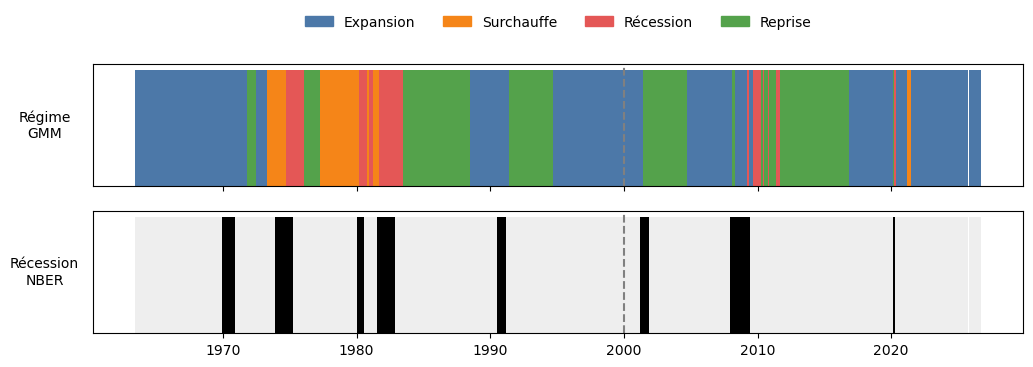

In [3]:
couleurs = {0: "#4C78A8", 1: "#F58518", 2: "#E45756", 3: "#54A24B"}
noms_reg = {0: "Expansion", 1: "Surchauffe", 2: "Récession", 3: "Reprise"}

fig, ax = plt.subplots(2, 1, figsize=(12, 3.5), sharex=True)
ax[0].bar(regimes.index, 1, width=31, color=[couleurs[r] for r in regimes])
ax[1].bar(usrec.index, 1, width=31, color=["black" if u == 1 else "#EEEEEE" for u in usrec])

ax[0].set_yticks([]); ax[1].set_yticks([])
ax[0].set_ylabel("Régime\nGMM", rotation=0, labelpad=35, va="center")
ax[1].set_ylabel("Récession\nNBER", rotation=0, labelpad=35, va="center")
for a in ax:
    a.axvline(pd.Timestamp("2000-01-01"), color="grey", linestyle="--")

from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=couleurs[r], label=noms_reg[r]) for r in range(4)],
             ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.5), frameon=False)
plt.savefig(FIG / "fig1_regimes_nber.png", dpi=200, bbox_inches="tight")
plt.show()

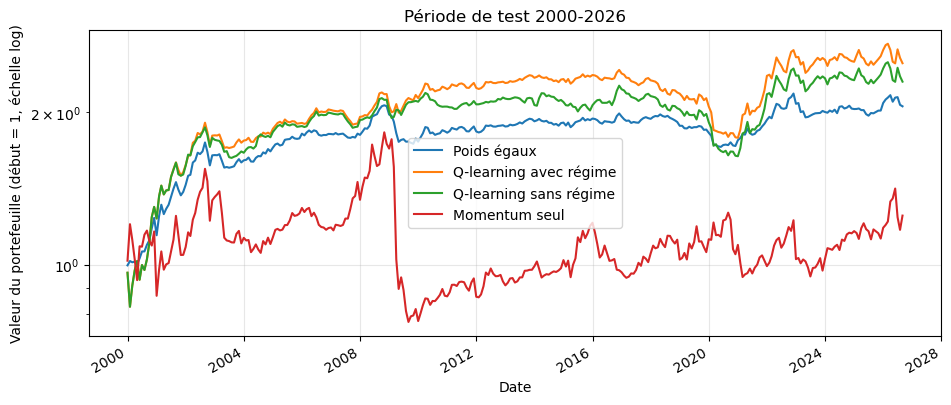

                        rendement_cumule  sharpe  max_drawdown
Poids égaux                        1.055   0.472        -0.172
Q-learning avec régime             1.499   0.426        -0.266
Q-learning sans régime             1.299   0.390        -0.274
Momentum seul                      0.250   0.141        -0.578


In [4]:
RISK, SEED = 50, 0
R_train = train[FACT].values
Q_reg = train_q(R_train, train["regime_lag"].values, 4, risk=RISK, seed=SEED)
Q_noreg = train_q(R_train, np.zeros(len(train), dtype=int), 1, risk=RISK, seed=SEED)

strats = pd.DataFrame({
    "Poids égaux": test[FACT].mean(axis=1),
    "Q-learning avec régime": evaluer(Q_reg, test, True),
    "Q-learning sans régime": evaluer(Q_noreg, test, False),
    "Momentum seul": test["momentum"],
})
cum = (1 + strats).cumprod()

cum.plot(figsize=(11, 4.5), logy=True)
plt.ylabel("Valeur du portefeuille (début = 1, échelle log)")
plt.title("Période de test 2000-2026")
plt.grid(alpha=0.3)
plt.savefig(FIG / "fig2_rendements_test.png", dpi=200, bbox_inches="tight")
plt.show()
perf_fig2 = pd.DataFrame({c: perf(strats[c]) for c in strats.columns}).T.round(3)
perf_fig2.to_csv(DATA.parent / "results" / "fig2_performance_test.csv")
print(perf_fig2)